In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

print("Bibliothèques chargées avec succès !")

Bibliothèques chargées avec succès !


In [2]:
df = pd.read_csv("supermarket_sales_100k.csv")

# Ajustement robuste des heures (format HH:MM)
df['heure_num'] = df['heure_achat'].astype(str).str.split(':').str[0].astype(int)
df['date_achat'] = pd.to_datetime(df['date_achat'])

df.head(5)

,ticket_id,client_id,age,sexe,quartier,type_client,date_achat,heure_achat,jour_semaine,mois,...,rayon_id,rayon,position_rayon,niveau_rayon,quantite,prix_unitaire,prix_total,promotion,taux_reduction,heure_num
0,T000001,C003177,30.0,F,Chimpunda,Régulier,2025-01-01,08:12,Mercredi,1,...,R0009,Surgelés,position_02,milieu,1,2.25,2.25,0,0.0,8
1,T000002,C003552,50.0,F,Kawa,Régulier,2025-01-01,08:18,Mercredi,1,...,R0003,Crèmerie,position_14,milieu,1,1.25,1.25,0,0.0,8
2,T000002,C003552,50.0,F,Kawa,Régulier,2025-01-01,08:18,Mercredi,1,...,R0022,Hygiène & Soins,position_15,milieu,2,2.25,4.05,1,0.1,8
3,T000003,C000323,58.0,M,Museye,Régulier,2025-01-01,08:33,Mercredi,1,...,R0011,Épicerie Sèche,position_18,bas,1,1.75,1.75,0,0.0,8
4,T000003,C000323,58.0,M,Museye,Régulier,2025-01-01,08:33,Mercredi,1,...,R0011,Épicerie Sèche,position_02,milieu,1,2.50,2.50,0,0.0,8


In [3]:
df.shape

(100233, 26)

In [4]:
ca_total = df['prix_total'].sum()
nb_tickets = df['ticket_id'].nunique()
nb_clients = df['client_id'].nunique()

print(f"Chiffre d'affaires total : {ca_total:,.2f} $")
print(f"Nombre de clients uniques: {nb_clients:,}")
print(f"Nombre de tickets (paniers): {nb_tickets:,}")
print(f"Panier moyen : {ca_total / nb_tickets:.2f} $")

Chiffre d'affaires total : 328,818.08 $
Nombre de clients uniques: 6,000
Nombre de tickets (paniers): 32,729
Panier moyen : 10.05 $


/tmp/ipykernel_64886/3864959641.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=labels, y=counts_grouped.values, palette="mako")


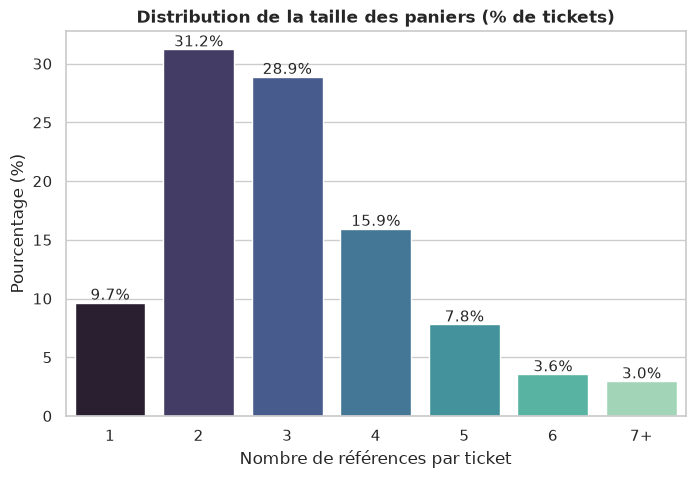

In [5]:
panier_stats = df.groupby('ticket_id')['produit_id'].count()
counts_panier = panier_stats.value_counts(normalize=True).sort_index() * 100

# Regroupement 7+
counts_grouped = counts_panier.head(6)
counts_grouped[7] = counts_panier[counts_panier.index >= 7].sum()
labels = [str(i) for i in range(1, 7)] + ['7+']

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=labels, y=counts_grouped.values, palette="mako")
plt.title("Distribution de la taille des paniers (% de tickets)", fontweight='bold')
plt.xlabel("Nombre de références par ticket")
plt.ylabel("Pourcentage (%)")

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

/tmp/ipykernel_64886/3751851045.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=jour_sales.index, y=jour_sales.values, palette="Blues_d")


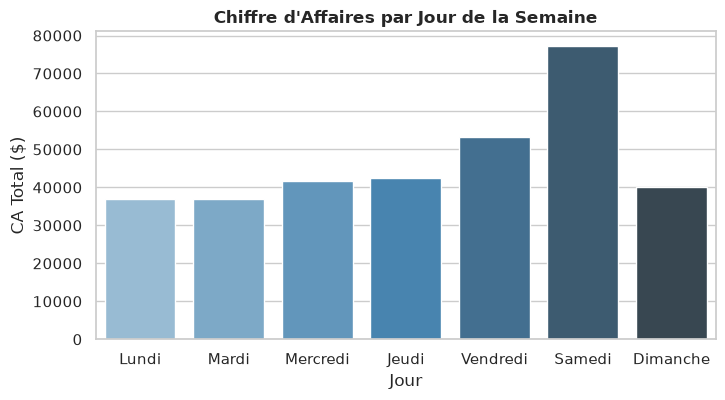

In [6]:
jours_ordre = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi', 'Samedi', 'Dimanche']
jour_sales = df.groupby('jour_semaine')['prix_total'].sum().reindex(jours_ordre)

plt.figure(figsize=(8, 4))
sns.barplot(x=jour_sales.index, y=jour_sales.values, palette="Blues_d")
plt.title("Chiffre d'Affaires par Jour de la Semaine", fontweight='bold')
plt.xlabel("Jour")
plt.ylabel("CA Total ($)")
plt.show()

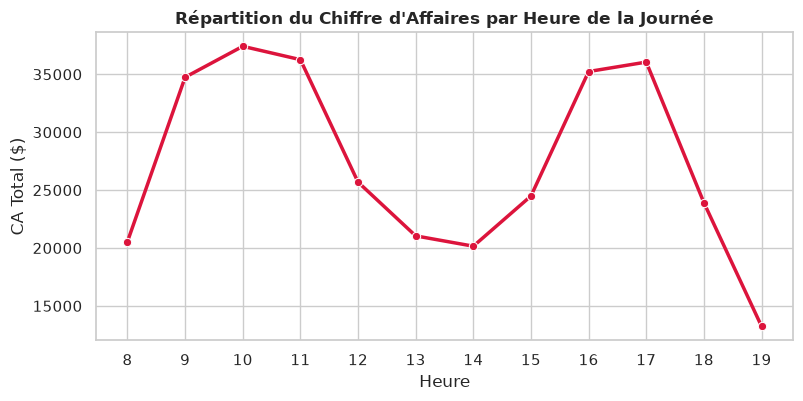

In [7]:
hourly_sales = df.groupby('heure_num')['prix_total'].sum()

plt.figure(figsize=(9, 4))
sns.lineplot(x=hourly_sales.index, y=hourly_sales.values, marker='o', color='crimson', linewidth=2.5)
plt.title("Répartition du Chiffre d'Affaires par Heure de la Journée", fontweight='bold')
plt.xlabel("Heure")
plt.ylabel("CA Total ($)")
plt.xticks(range(int(df['heure_num'].min()), int(df['heure_num'].max()) + 1))
plt.show()

/tmp/ipykernel_64886/403702231.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=promo_impact, x='promotion', y='quantite', palette="Set2")


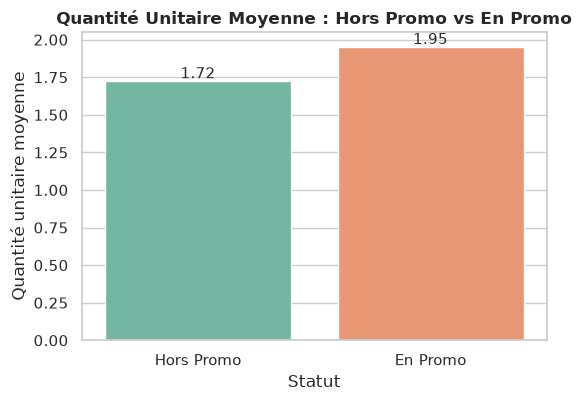

In [8]:
promo_impact = df.groupby('promotion')['quantite'].mean().reset_index()
promo_impact['promotion'] = promo_impact['promotion'].map({0: 'Hors Promo', 1: 'En Promo'})

plt.figure(figsize=(6, 4))
ax = sns.barplot(data=promo_impact, x='promotion', y='quantite', palette="Set2")
plt.title("Quantité Unitaire Moyenne : Hors Promo vs En Promo", fontweight='bold')
plt.ylabel("Quantité unitaire moyenne")
plt.xlabel("Statut")

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.show()

/tmp/ipykernel_64886/505679250.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rayon_villes.values, y=rayon_villes.index, palette="cubehelix")


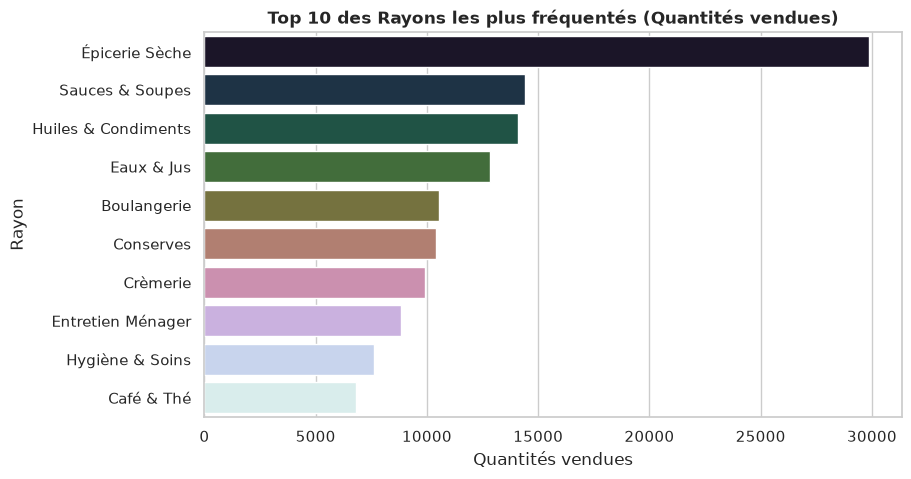

In [9]:
rayon_villes = df.groupby('rayon')['quantite'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=rayon_villes.values, y=rayon_villes.index, palette="cubehelix")
plt.title("Top 10 des Rayons les plus fréquentés (Quantités vendues)", fontweight='bold')
plt.xlabel("Quantités vendues")
plt.ylabel("Rayon")
plt.show()

/tmp/ipykernel_64886/1649366959.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='quantite', ax=axes[1, 0], palette='Blues_d')


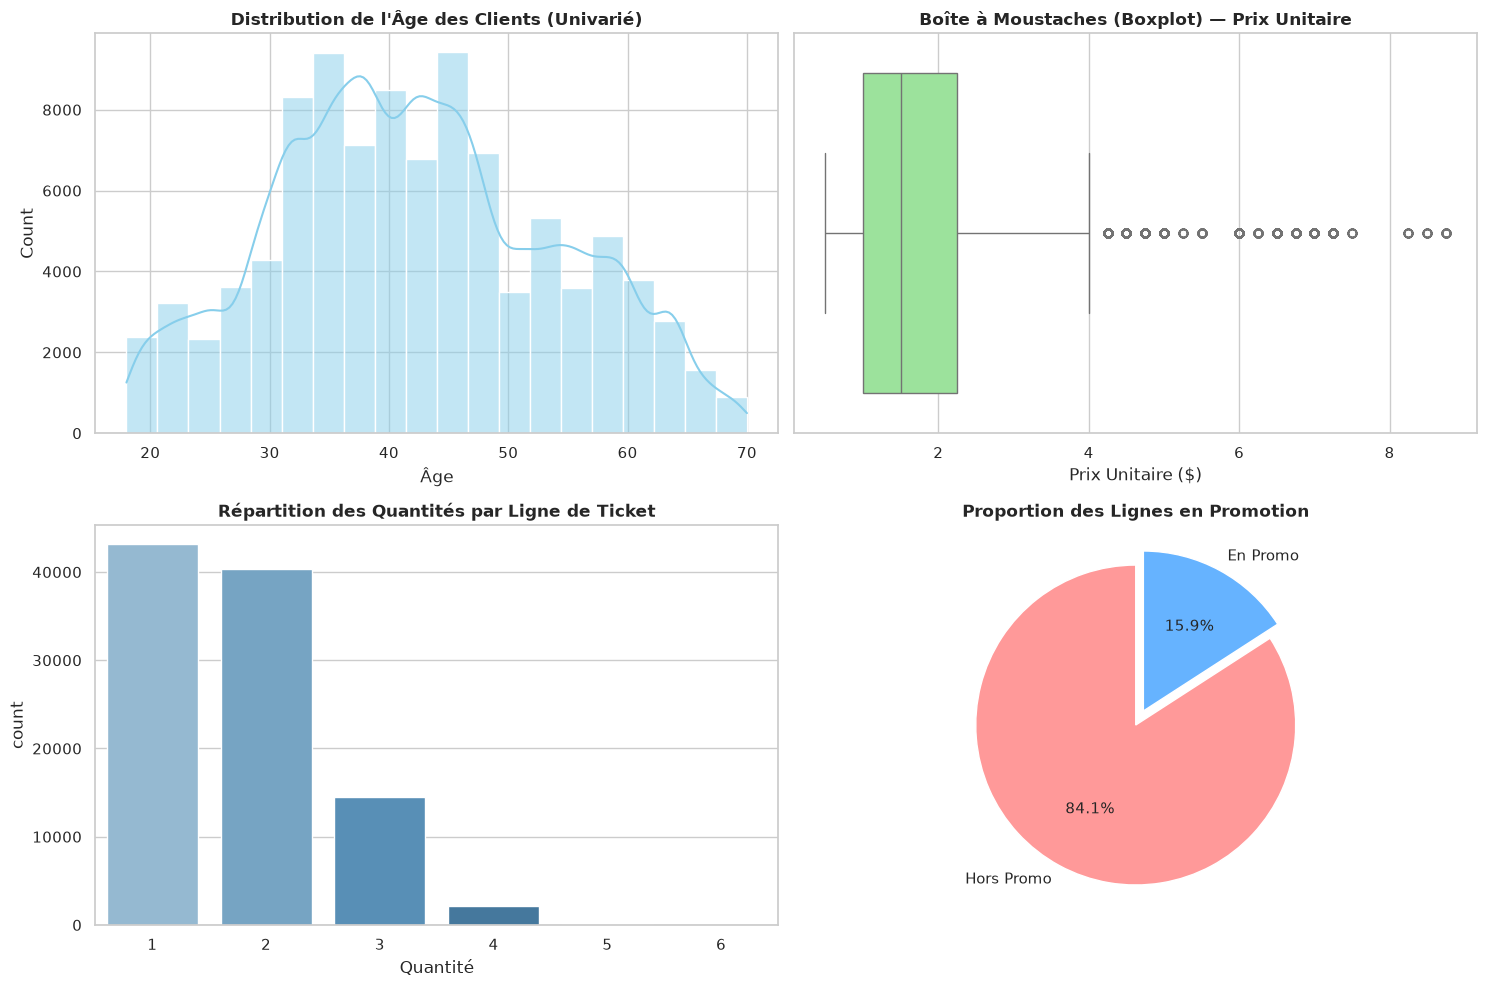

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Distribution de l'âge des clients
sns.histplot(df['age'].dropna(), kde=True, ax=axes[0, 0], color='skyblue', bins=20)
axes[0, 0].set_title("Distribution de l'Âge des Clients (Univarié)", fontweight='bold')
axes[0, 0].set_xlabel("Âge")

# 2. Distribution des prix unitaires (échelle logarithmique si forte asymétrie)
sns.boxplot(x=df['prix_unitaire'], ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title("Boîte à Moustaches (Boxplot) — Prix Unitaire", fontweight='bold')
axes[0, 1].set_xlabel("Prix Unitaire ($)")

# 3. Distribution des quantités achetées par ligne
sns.countplot(data=df, x='quantite', ax=axes[1, 0], palette='Blues_d')
axes[1, 0].set_title("Répartition des Quantités par Ligne de Ticket", fontweight='bold')
axes[1, 0].set_xlabel("Quantité")

# 4. Proportion de lignes sous Promotion
df['promotion'].value_counts(normalize=True).plot.pie(
    ax=axes[1, 1], 
    autopct='%1.1f%%', 
    colors=['#ff9999','#66b3ff'], 
    labels=['Hors Promo', 'En Promo'],
    startangle=90,
    explode=(0, 0.1)
)
axes[1, 1].set_title("Proportion des Lignes en Promotion", fontweight='bold')
axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()

/tmp/ipykernel_64886/3569939680.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='quartier', order=order_quartier, ax=axes[0], palette='magma')
/tmp/ipykernel_64886/3569939680.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='niveau_rayon', order=['haut', 'milieu', 'bas'], ax=axes[1], palette='rocket')


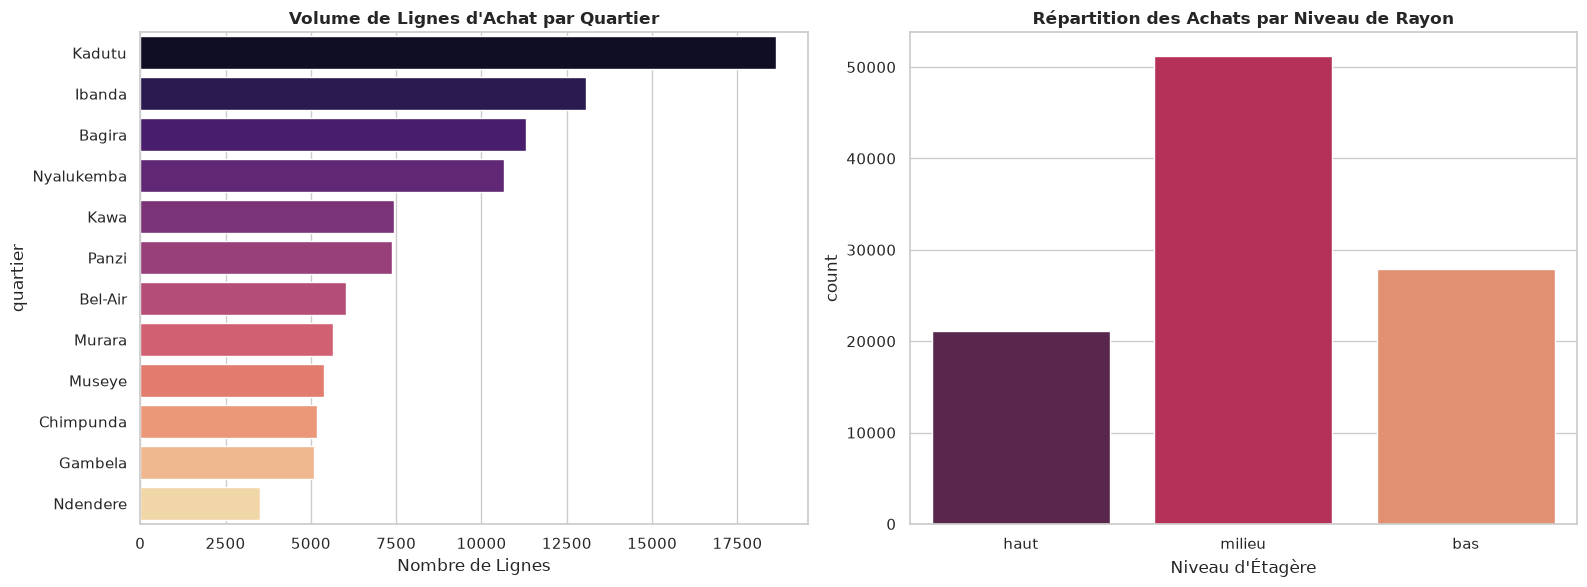

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Répartition des acheteurs par Quartier
order_quartier = df['quartier'].value_counts().index
sns.countplot(data=df, y='quartier', order=order_quartier, ax=axes[0], palette='magma')
axes[0].set_title("Volume de Lignes d'Achat par Quartier", fontweight='bold')
axes[0].set_xlabel("Nombre de Lignes")

# Répartition des ventes par Niveau de Rayon (Haut, Milieu, Bas)
sns.countplot(data=df, x='niveau_rayon', order=['haut', 'milieu', 'bas'], ax=axes[1], palette='rocket')
axes[1].set_title("Répartition des Achats par Niveau de Rayon", fontweight='bold')
axes[1].set_xlabel("Niveau d'Étagère")

plt.tight_layout()
plt.show()

/tmp/ipykernel_64886/1104418031.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_cats, x='prix_unitaire', y='categorie', ax=axes[0], palette='Set3')
/tmp/ipykernel_64886/1104418031.py:12: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df[df['promotion'] == 1], x='taux_reduction', y='quantite', ax=axes[1], ci=None, palette='mako')
/tmp/ipykernel_64886/1104418031.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df[df['promotion'] == 1], x='taux_reduction', y='quantite', ax=axes[1], ci=None, palette='mako')


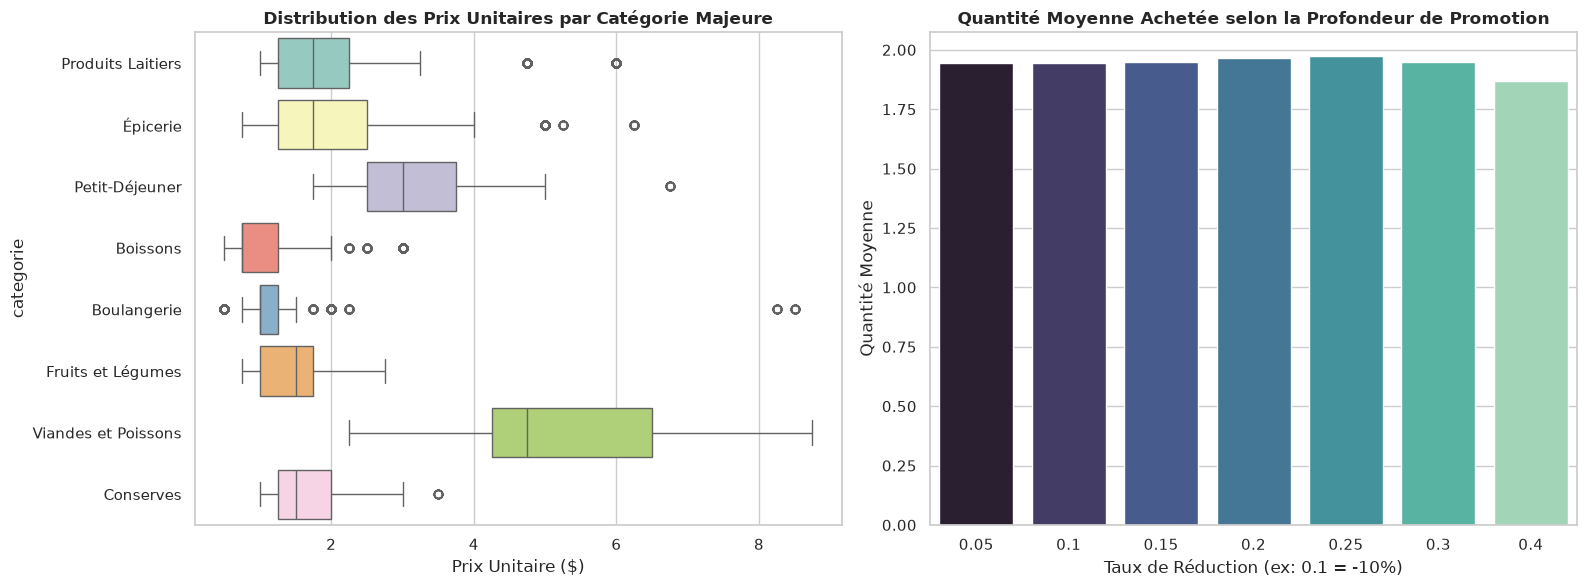

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Distribution du Prix Unitaire par Catégorie (Boxplot bivarié)
top_cats = df.groupby('categorie')['prix_total'].sum().nlargest(8).index
df_top_cats = df[df['categorie'].isin(top_cats)]

sns.boxplot(data=df_top_cats, x='prix_unitaire', y='categorie', ax=axes[0], palette='Set3')
axes[0].set_title("Distribution des Prix Unitaires par Catégorie Majeure", fontweight='bold')
axes[0].set_xlabel("Prix Unitaire ($)")

# 2. Relation entre le Taux de Réduction et la Quantité Achetée (Barplot bivarié)
sns.barplot(data=df[df['promotion'] == 1], x='taux_reduction', y='quantite', ax=axes[1], ci=None, palette='mako')
axes[1].set_title("Quantité Moyenne Achetée selon la Profondeur de Promotion", fontweight='bold')
axes[1].set_xlabel("Taux de Réduction (ex: 0.1 = -10%)")
axes[1].set_ylabel("Quantité Moyenne")

plt.tight_layout()
plt.show()

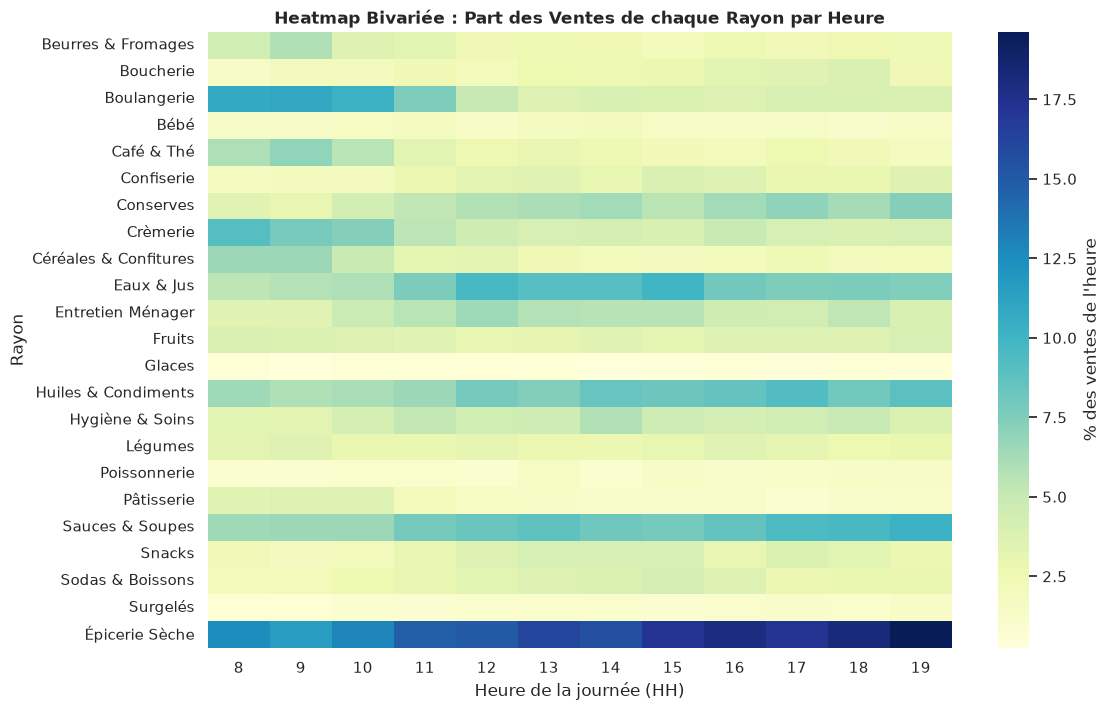

In [13]:
plt.figure(figsize=(12, 8))

# Matrice de croisement entre les Rayons et l'Heure d'Achat
pivot_rayon_heure = pd.crosstab(df['rayon'], df['heure_num'], normalize='columns') * 100

sns.heatmap(pivot_rayon_heure, cmap="YlGnBu", annot=False, cbar_kws={'label': '% des ventes de l\'heure'})
plt.title("Heatmap Bivariée : Part des Ventes de chaque Rayon par Heure", fontweight='bold')
plt.xlabel("Heure de la journée (HH)")
plt.ylabel("Rayon")
plt.show()

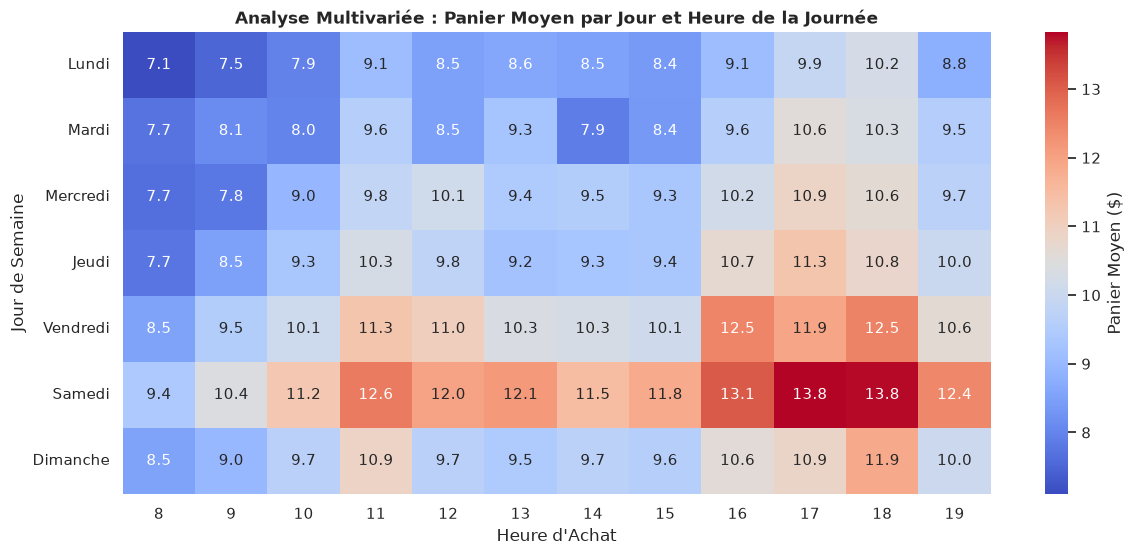

In [14]:
# 1. Croisement : Jour de Semaine × Heure × Panier Moyen
panier_multivarie = df.groupby(['ticket_id', 'jour_semaine', 'heure_num']).agg(
    montant_ticket=('prix_total', 'sum')
).reset_index()

jours_ordre = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi', 'Samedi', 'Dimanche']
pivot_heatmap = panier_multivarie.pivot_table(
    index='jour_semaine', 
    columns='heure_num', 
    values='montant_ticket', 
    aggfunc='mean'
).reindex(jours_ordre)

plt.figure(figsize=(14, 6))
sns.heatmap(pivot_heatmap, cmap="coolwarm", annot=True, fmt=".1f", cbar_kws={'label': 'Panier Moyen ($)'})
plt.title("Analyse Multivariée : Panier Moyen par Jour et Heure de la Journée", fontweight='bold')
plt.xlabel("Heure d'Achat")
plt.ylabel("Jour de Semaine")
plt.show()

/tmp/ipykernel_64886/1168992899.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


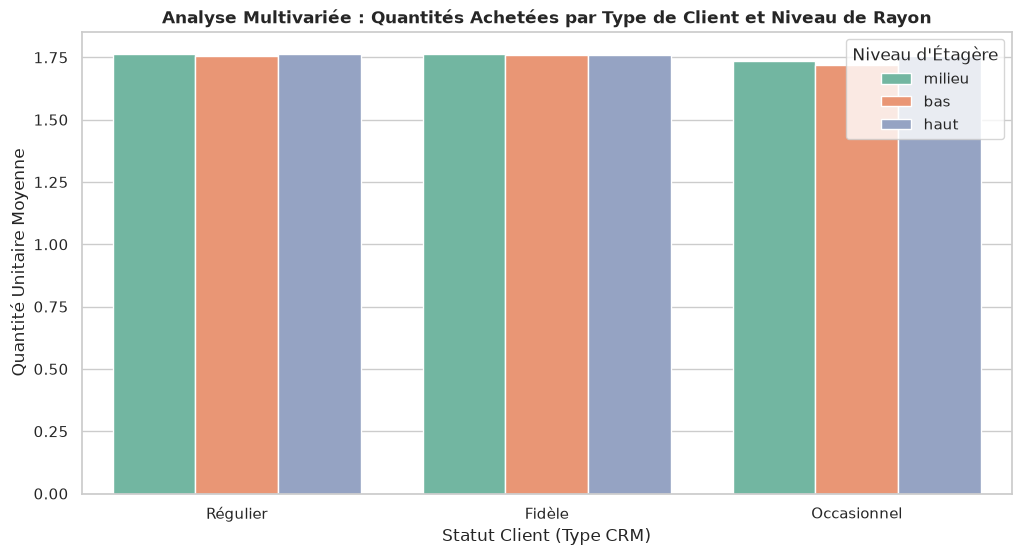

In [15]:
plt.figure(figsize=(12, 6))

# Croisement : Type de Client (CRM) × Niveau de Rayon × Quantité Moyenne
sns.barplot(
    data=df, 
    x='type_client', 
    y='quantite', 
    hue='niveau_rayon', 
    palette='Set2', 
    ci=None
)
plt.title("Analyse Multivariée : Quantités Achetées par Type de Client et Niveau de Rayon", fontweight='bold')
plt.xlabel("Statut Client (Type CRM)")
plt.ylabel("Quantité Unitaire Moyenne")
plt.legend(title="Niveau d'Étagère")
plt.show()

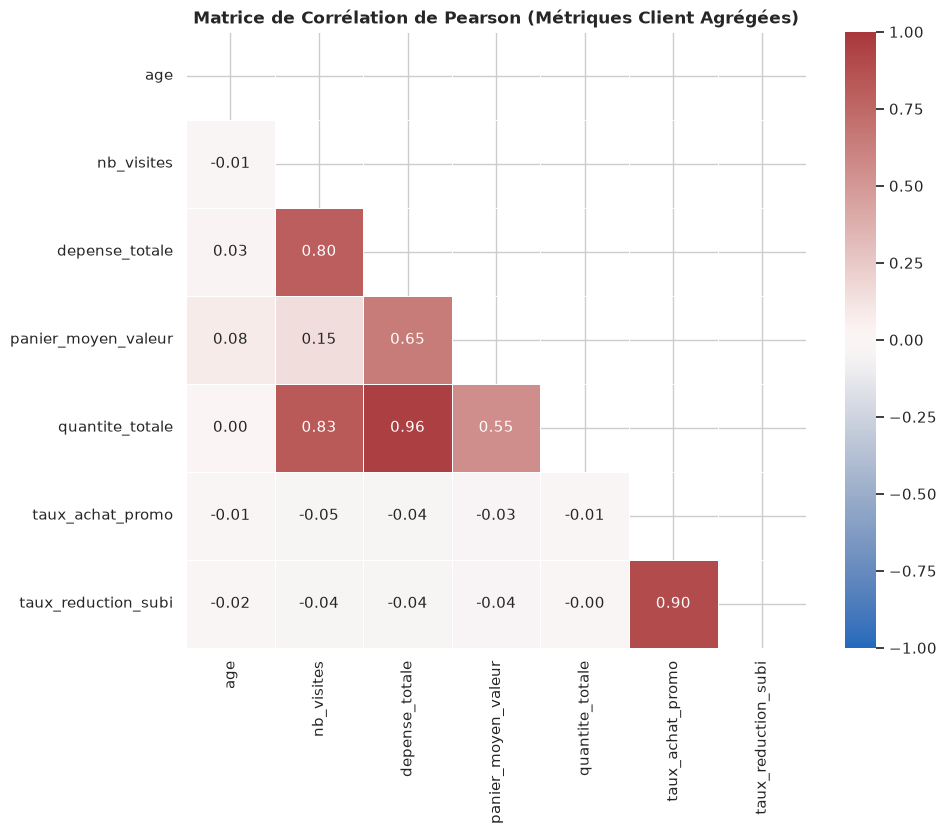

In [16]:
# 1. Agrégation des métriques au niveau Client (Feature Matrix)
client_metrics = df.groupby('client_id').agg(
    age=('age', 'first'),
    nb_visites=('ticket_id', 'nunique'),
    depense_totale=('prix_total', 'sum'),
    panier_moyen_valeur=('prix_total', lambda x: x.sum() / df.loc[x.index, 'ticket_id'].nunique()),
    quantite_totale=('quantite', 'sum'),
    taux_achat_promo=('promotion', 'mean'),
    taux_reduction_subi=('taux_reduction', 'mean')
).dropna()

# 2. Calcul de la matrice de corrélation
corr_matrix = client_metrics.corr(method='pearson')

# 3. Affichage du Heatmap de Corrélation
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Masque pour la moitié supérieure

sns.heatmap(
    corr_matrix, 
    mask=mask,
    annot=True, 
    fmt=".2f", 
    cmap="vlag", 
    vmin=-1, vmax=1, 
    linewidths=0.5
)
plt.title("Matrice de Corrélation de Pearson (Métriques Client Agrégées)", fontweight='bold')
plt.show()

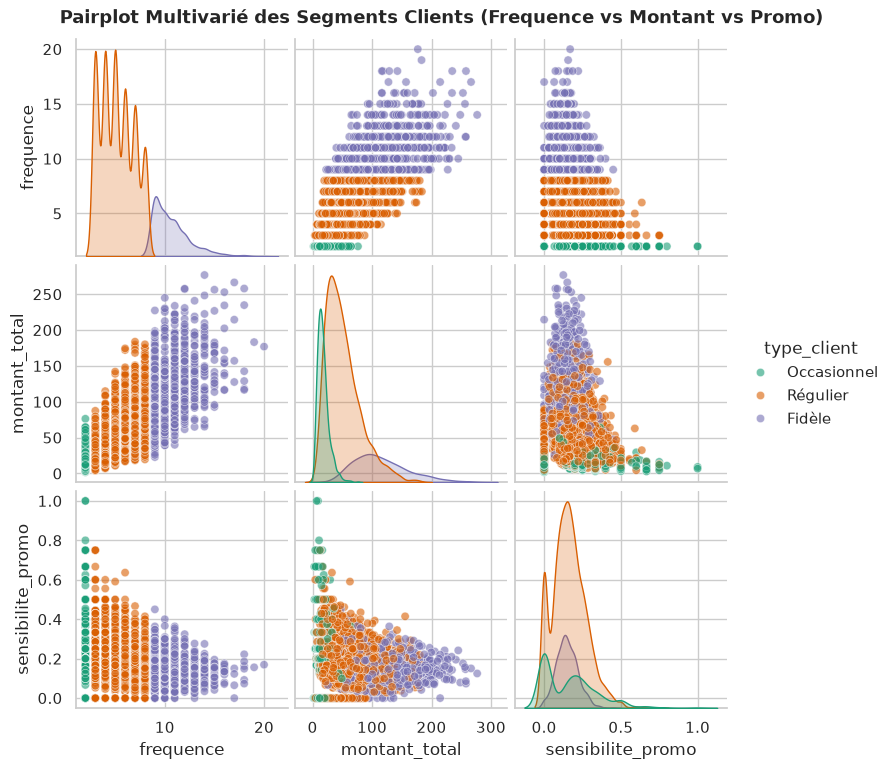

In [17]:
# Sélection d'un échantillon représentatif de métriques clients avec le Type de Client
sample_clients = df.groupby('client_id').agg(
    frequence=('ticket_id', 'nunique'),
    montant_total=('prix_total', 'sum'),
    sensibilite_promo=('promotion', 'mean'),
    type_client=('type_client', 'first')
).reset_index()

# Pairplot coloré par Type de Client
sns.pairplot(
    sample_clients, 
    vars=['frequence', 'montant_total', 'sensibilite_promo'], 
    hue='type_client', 
    palette='Dark2',
    plot_kws={'alpha': 0.6}
)
plt.suptitle("Pairplot Multivarié des Segments Clients (Frequence vs Montant vs Promo)", y=1.02, fontweight='bold')
plt.show()

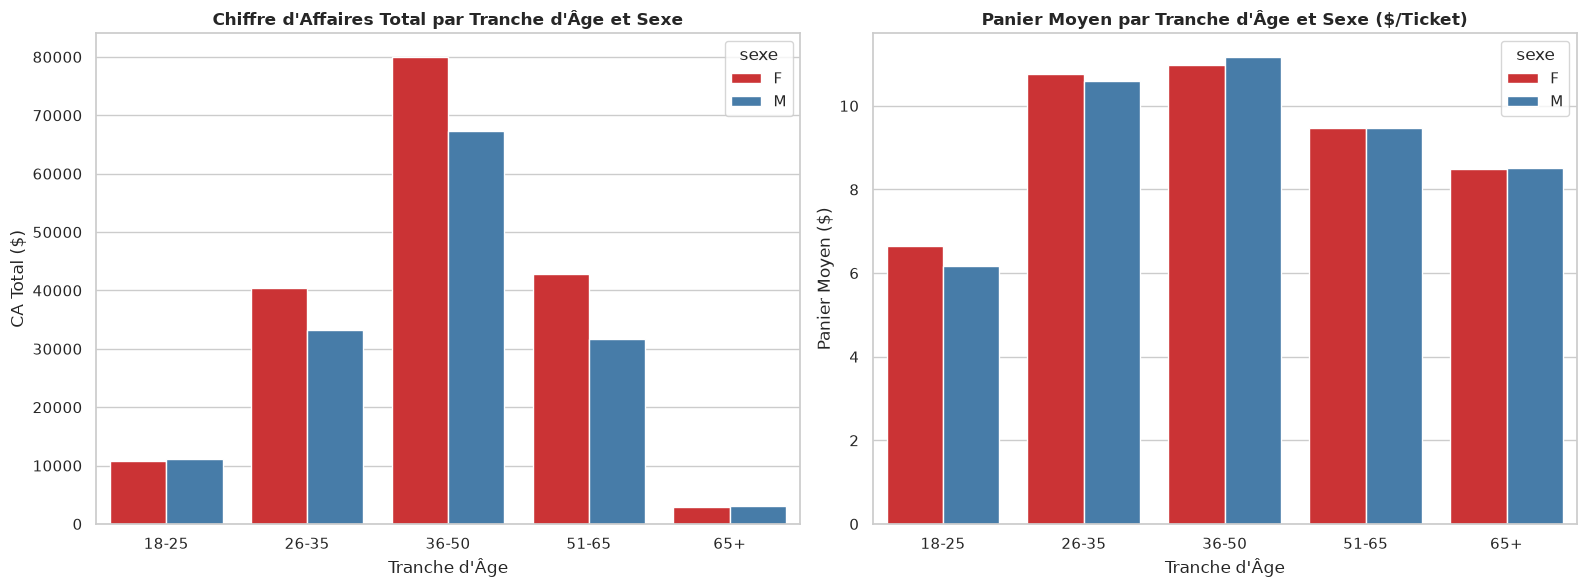

In [18]:
# 1. Création de tranches d'âge
bins = [17, 25, 35, 50, 65, 100]
labels = ['18-25', '26-35', '36-50', '51-65', '65+']
df['tranche_age'] = pd.cut(df['age'], bins=bins, labels=labels)

# 2. Agrégation par Tranche d'Âge et Sexe
demo_stats = df.groupby(['tranche_age', 'sexe'], observed=True).agg(
    ca_total=('prix_total', 'sum'),
    nb_tickets=('ticket_id', 'nunique'),
    nb_clients=('client_id', 'nunique'),
    quantite_totale=('quantite', 'sum')
).reset_index()

demo_stats['panier_moyen'] = demo_stats['ca_total'] / demo_stats['nb_tickets']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique A : Chiffre d'Affaires Total par Âge et Sexe
sns.barplot(data=demo_stats, x='tranche_age', y='ca_total', hue='sexe', ax=axes[0], palette='Set1')
axes[0].set_title("Chiffre d'Affaires Total par Tranche d'Âge et Sexe", fontweight='bold')
axes[0].set_xlabel("Tranche d'Âge")
axes[0].set_ylabel("CA Total ($)")

# Graphique B : Panier Moyen ($) par Âge et Sexe
sns.barplot(data=demo_stats, x='tranche_age', y='panier_moyen', hue='sexe', ax=axes[1], palette='Set1')
axes[1].set_title("Panier Moyen par Tranche d'Âge et Sexe ($/Ticket)", fontweight='bold')
axes[1].set_xlabel("Tranche d'Âge")
axes[1].set_ylabel("Panier Moyen ($)")

plt.tight_layout()
plt.show()

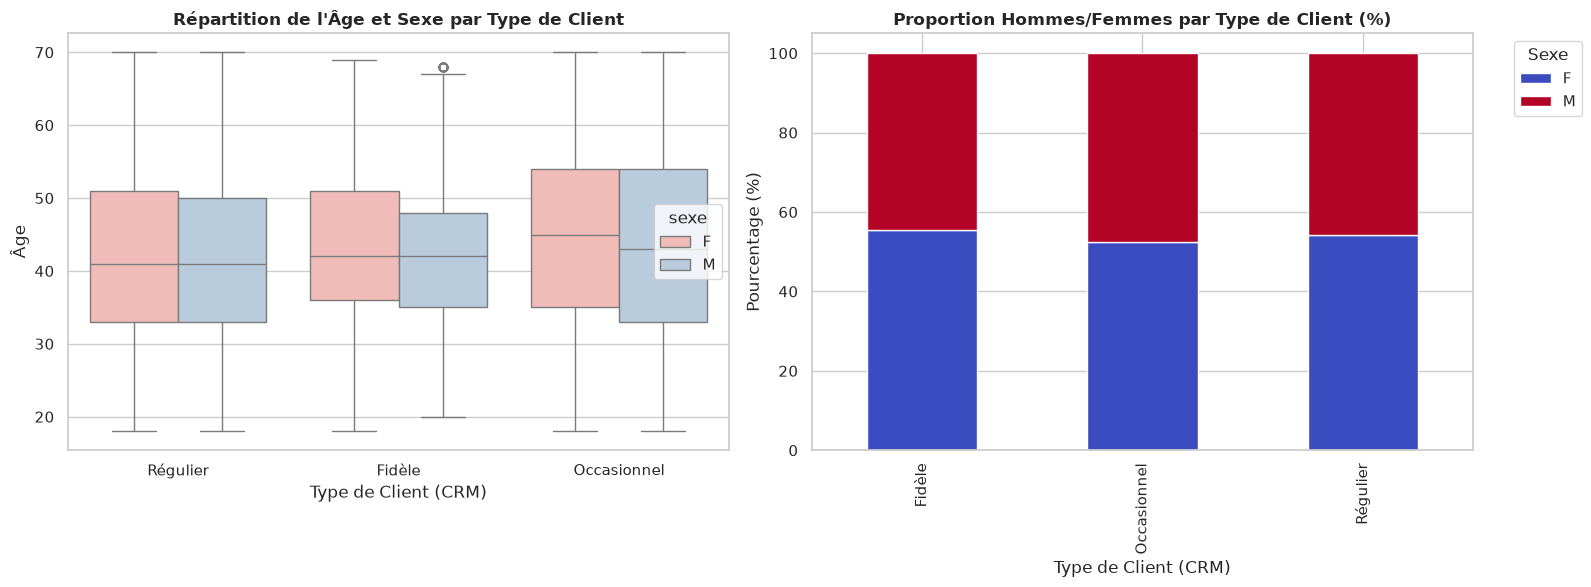

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Distribution de l'Âge par Type de Client (Boxplot)
sns.boxplot(data=df, x='type_client', y='age', hue='sexe', ax=axes[0], palette='Pastel1')
axes[0].set_title("Répartition de l'Âge et Sexe par Type de Client", fontweight='bold')
axes[0].set_xlabel("Type de Client (CRM)")
axes[0].set_ylabel("Âge")

# 2. Composition (Proportion des sexes) par Type de Client
sexe_type_cross = pd.crosstab(df['type_client'], df['sexe'], normalize='index') * 100
sexe_type_cross.plot(kind='bar', stacked=True, ax=axes[1], colormap='coolwarm')
axes[1].set_title("Proportion Hommes/Femmes par Type de Client (%)", fontweight='bold')
axes[1].set_xlabel("Type de Client (CRM)")
axes[1].set_ylabel("Pourcentage (%)")
axes[1].legend(title="Sexe", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

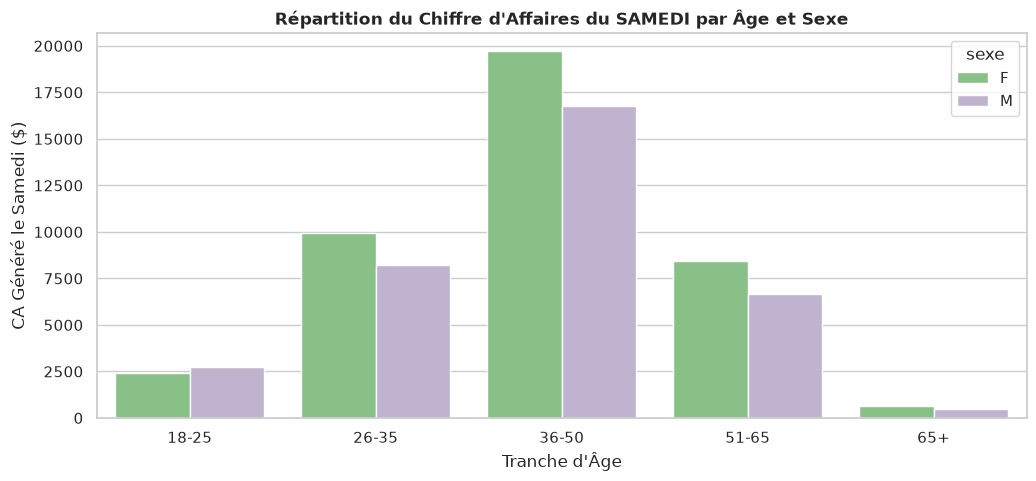

--- Dépendance au Samedi par Tranche d'Âge ---


,Part_CA_Samedi_%
tranche_age,
18-25,23.60
26-35,24.65
36-50,24.74
51-65,20.29
65+,18.26


In [20]:
# Filtrer sur le Samedi vs Reste de la semaine
df_samedi = df[df['jour_semaine'] == 'Samedi']

# Top catégories d'acheteurs du samedi
samedi_demo = df_samedi.groupby(['tranche_age', 'sexe'], observed=True).agg(
    ca_samedi=('prix_total', 'sum'),
    frequentation=('ticket_id', 'nunique')
).reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=samedi_demo, x='tranche_age', y='ca_samedi', hue='sexe', palette='Accent')
plt.title("Répartition du Chiffre d'Affaires du SAMEDI par Âge et Sexe", fontweight='bold')
plt.xlabel("Tranche d'Âge")
plt.ylabel("CA Généré le Samedi ($)")
plt.show()

# Tableau récapitulatif : Comparaison Part du Samedi vs Semaine par Tranche d'Âge
total_ca_semaine = df.groupby('tranche_age', observed=True)['prix_total'].sum()
samedi_ca = df_samedi.groupby('tranche_age', observed=True)['prix_total'].sum()
part_samedi = (samedi_ca / total_ca_semaine * 100).round(2).to_frame(name='Part_CA_Samedi_%')

print("--- Dépendance au Samedi par Tranche d'Âge ---")
display(part_samedi)

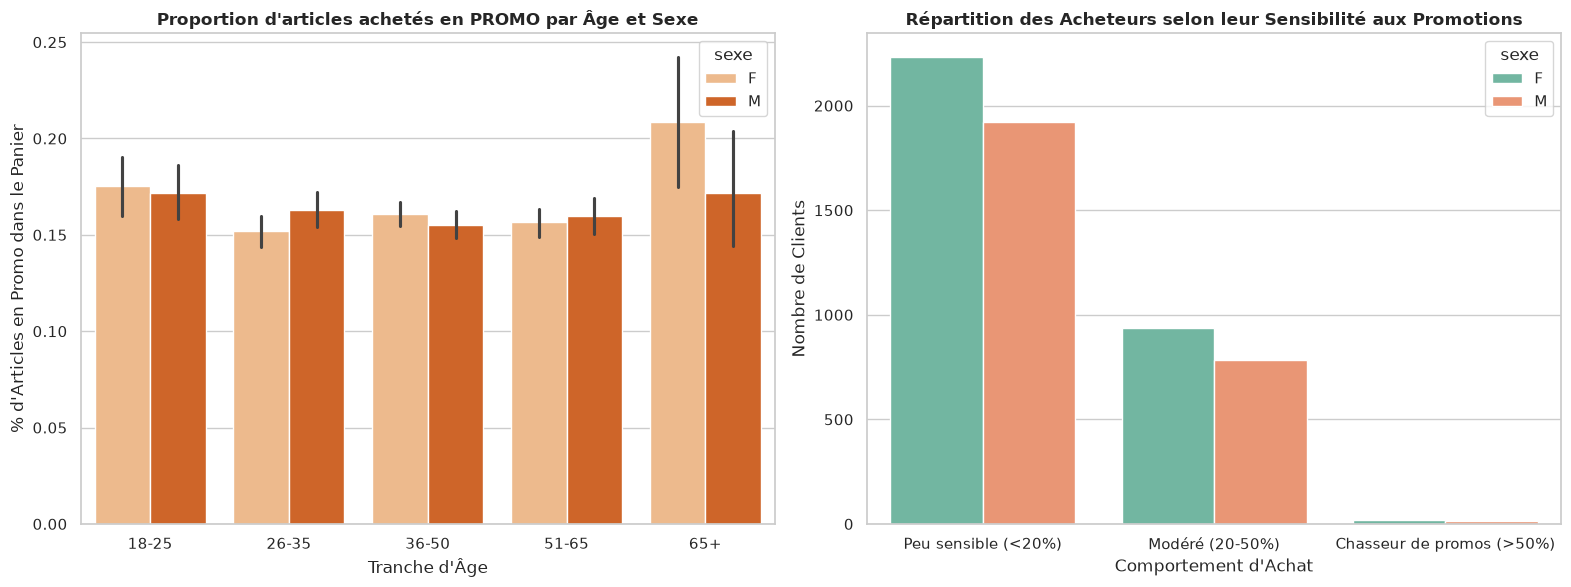

In [21]:
# Calcul du taux d'achat sous promotion par individu
client_promo = df.groupby(['client_id', 'sexe', 'tranche_age'], observed=True).agg(
    taux_promo=('promotion', 'mean'), # Proportion d'articles achetés en promo
    depense_promo=('prix_total', lambda x: x[df.loc[x.index, 'promotion'] == 1].sum()),
    depense_totale=('prix_total', 'sum')
).reset_index()

client_promo['part_budget_promo'] = (client_promo['depense_promo'] / client_promo['depense_totale']) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : Taux d'articles en promotion dans le panier par Âge et Sexe
sns.barplot(data=client_promo, x='tranche_age', y='taux_promo', hue='sexe', ax=axes[0], palette='Oranges')
axes[0].set_title("Proportion d'articles achetés en PROMO par Âge et Sexe", fontweight='bold')
axes[0].set_xlabel("Tranche d'Âge")
axes[0].set_ylabel("% d'Articles en Promo dans le Panier")

# Graphique 2 : Profil des acheteurs selon leur niveau d'addiction aux promos
client_promo['profil_promo'] = pd.cut(
    client_promo['taux_promo'], 
    bins=[-0.1, 0.2, 0.5, 1.0], 
    labels=['Peu sensible (<20%)', 'Modéré (20-50%)', 'Chasseur de promos (>50%)']
)

sns.countplot(data=client_promo, x='profil_promo', hue='sexe', ax=axes[1], palette='Set2')
axes[1].set_title("Répartition des Acheteurs selon leur Sensibilité aux Promotions", fontweight='bold')
axes[1].set_xlabel("Comportement d'Achat")
axes[1].set_ylabel("Nombre de Clients")

plt.tight_layout()
plt.show()

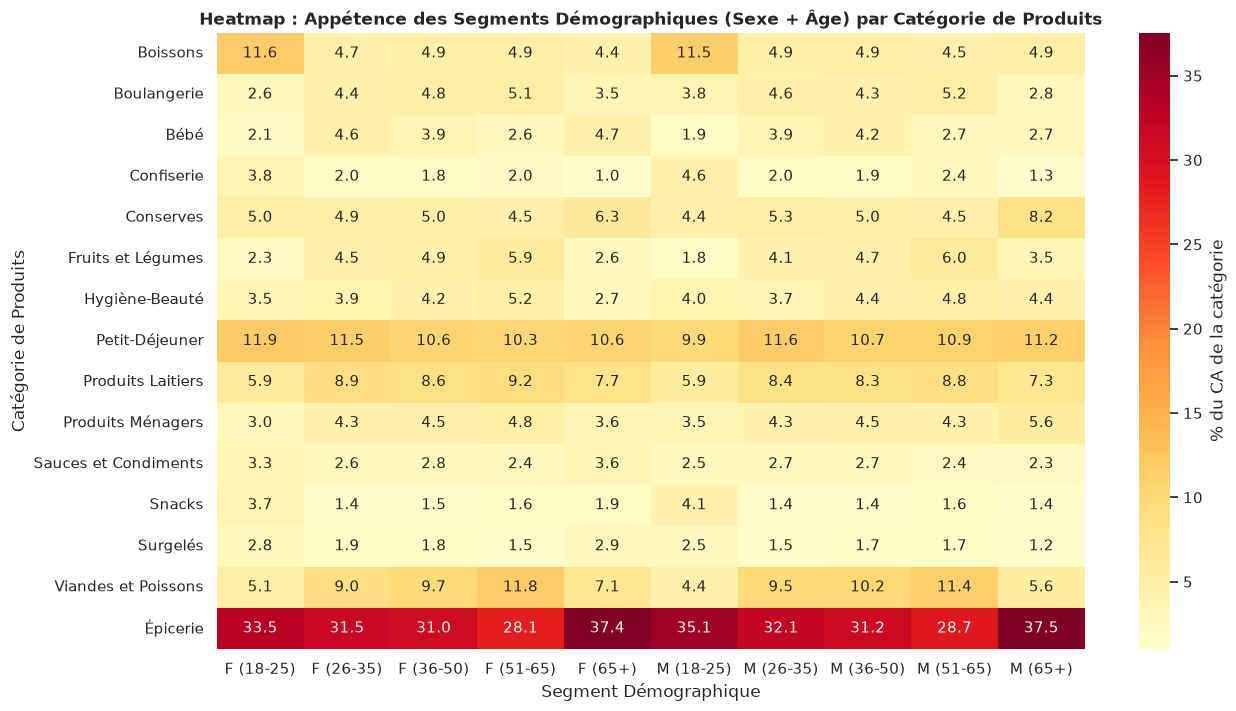

In [22]:
# Création d'une variable combinée Âge-Sexe
df['segment_demo'] = df['sexe'].astype(str) + " (" + df['tranche_age'].astype(str) + ")"

# Tableau croisé dynamisant la part de chaque catégorie par segment démographique
pivot_demo_cat = pd.crosstab(
    df['categorie'], 
    df['segment_demo'], 
    values=df['prix_total'], 
    aggfunc='sum', 
    normalize='columns'
) * 100

plt.figure(figsize=(14, 8))
sns.heatmap(pivot_demo_cat, cmap="YlOrRd", annot=True, fmt=".1f", cbar_kws={'label': '% du CA de la catégorie'})
plt.title("Heatmap : Appétence des Segments Démographiques (Sexe + Âge) par Catégorie de Produits", fontweight='bold')
plt.xlabel("Segment Démographique")
plt.ylabel("Catégorie de Produits")
plt.show()

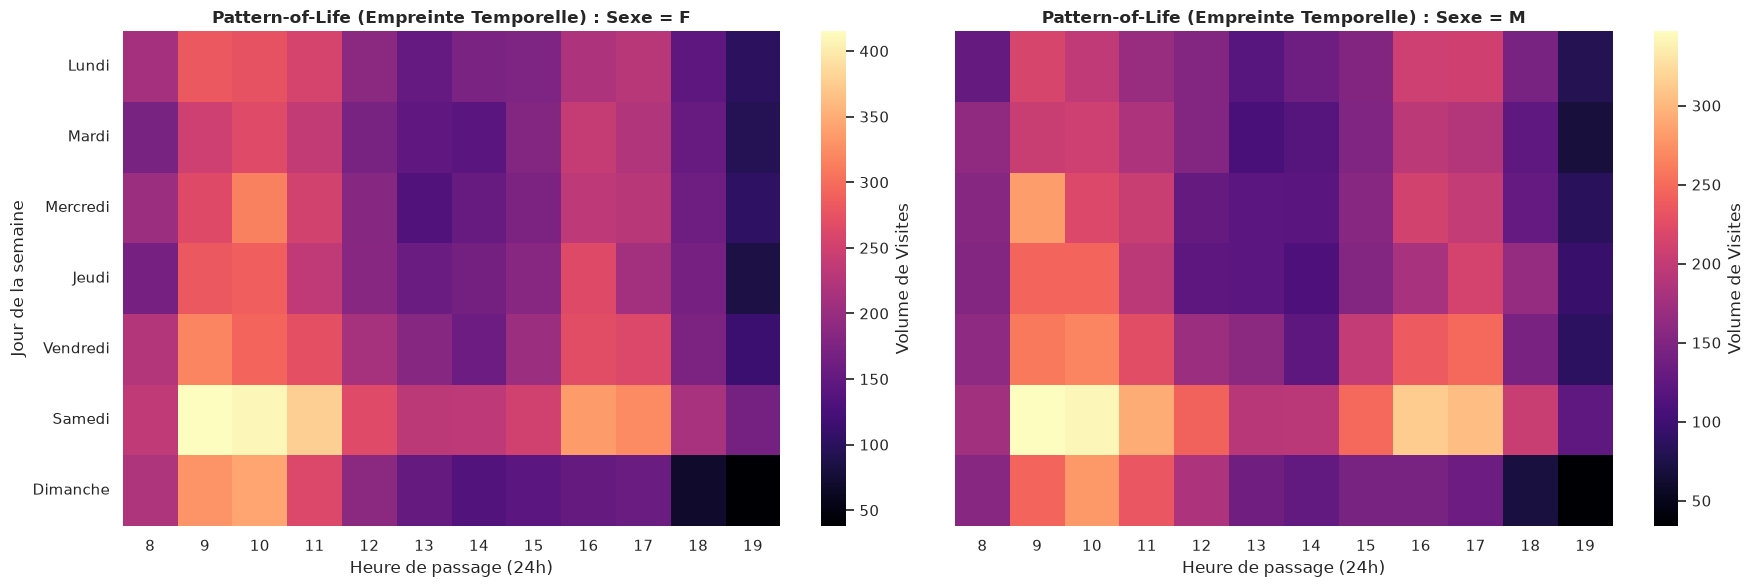

In [23]:
# 1. Aggrégation de la fréquentation par Heure, Jour et Sexe
pol_matrix = df.groupby(['jour_semaine', 'heure_num', 'sexe'], observed=True)['ticket_id'].nunique().reset_index()

# Tri par ordre logique de la semaine
jours_ordre = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi', 'Samedi', 'Dimanche']
pol_matrix['jour_semaine'] = pd.Categorical(pol_matrix['jour_semaine'], categories=jours_ordre, ordered=True)

# 2. Construction de la Heatmap comparative
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for i, sexe_val in enumerate(df['sexe'].unique()):
    data_sexe = pol_matrix[pol_matrix['sexe'] == sexe_val]
    pivot_pol = data_sexe.pivot_table(index='jour_semaine', columns='heure_num', values='ticket_id', fill_value=0)
    
    sns.heatmap(pivot_pol, ax=axes[i], cmap="magma", cbar_kws={'label': 'Volume de Visites'}, annot=False)
    axes[i].set_title(f"Pattern-of-Life (Empreinte Temporelle) : Sexe = {sexe_val}", fontweight='bold', fontsize=12)
    axes[i].set_xlabel("Heure de passage (24h)")
    axes[i].set_ylabel("Jour de la semaine" if i == 0 else "")

plt.tight_layout()
plt.show()

In [24]:
from itertools import combinations
from collections import Counter

def get_co_occurrences(dataframe, top_n=10):
    """
    Extrait les paires de produits les plus fréquemment achetées ensemble
    dans un même ticket.
    """
    # Grouper les produits par ticket
    tickets = dataframe.groupby('ticket_id')['categorie'].apply(set)
    
    # Compter les paires de catégories apparaissant ensemble
    pair_counts = Counter()
    for items in tickets:
        if len(items) > 1:
            for pair in combinations(sorted(items), 2):
                pair_counts[pair] += 1
                
    df_pairs = pd.DataFrame(pair_counts.most_common(top_n), columns=['Paire_Categories', 'Frequence_Achat'])
    return df_pairs

print("==================================================")
print("     SIGNATURES D'ACHAT (CO-OCCURRENCE CACHÉE)    ")
print("==================================================")

# Comparaison entre Acheteurs Agés (>50) vs Jeunes (18-35)
jeunes = df[df['age'] <= 35]
seniors = df[df['age'] >= 50]

print("\n--- TOP 5 DES PAIRES DE CATÉGORIES (JEUNES ≤ 35 ANS) ---")
display(get_co_occurrences(jeunes, top_n=5))

print("\n--- TOP 5 DES PAIRES DE CATÉGORIES (SENIORS ≥ 50 ANS) ---")
display(get_co_occurrences(seniors, top_n=5))

     SIGNATURES D'ACHAT (CO-OCCURRENCE CACHÉE)    

--- TOP 5 DES PAIRES DE CATÉGORIES (JEUNES ≤ 35 ANS) ---


,Paire_Categories,Frequence_Achat
0,"(Boissons, Épicerie)",1508
1,"(Produits Laitiers, Épicerie)",980
2,"(Petit-Déjeuner, Épicerie)",894
3,"(Boulangerie, Épicerie)",886
4,"(Conserves, Épicerie)",829



--- TOP 5 DES PAIRES DE CATÉGORIES (SENIORS ≥ 50 ANS) ---


,Paire_Categories,Frequence_Achat
0,"(Boissons, Épicerie)",1036
1,"(Produits Laitiers, Épicerie)",908
2,"(Boulangerie, Épicerie)",826
3,"(Fruits et Légumes, Épicerie)",736
4,"(Petit-Déjeuner, Épicerie)",639


Nombre d'individus identifiés comme 'Outliers / Profils Atypiques' : 147 / 6000

--- ÉCHANTILLON DES PROFILS ATYPIQUES (BALEINES / ACHATEURS EXTRÊMES) ---


,client_id,sexe,age,total_depense,panier_moyen,taux_promo
10,C000011,M,35.0,226.83,15.122000,0.166667
102,C000103,M,48.0,219.00,16.846154,0.142857
130,C000131,M,34.0,184.77,15.397500,0.166667
197,C000198,M,45.0,195.07,17.733636,0.102041
219,C000220,M,27.0,50.44,25.220000,0.100000
242,C000243,F,46.0,123.50,24.700000,0.333333
280,C000281,F,52.0,228.52,22.852000,0.111111
331,C000332,F,30.0,195.21,17.746364,0.180000
351,C000352,M,46.0,185.62,13.258571,0.078431
376,C000377,F,40.0,217.96,19.814545,0.125000


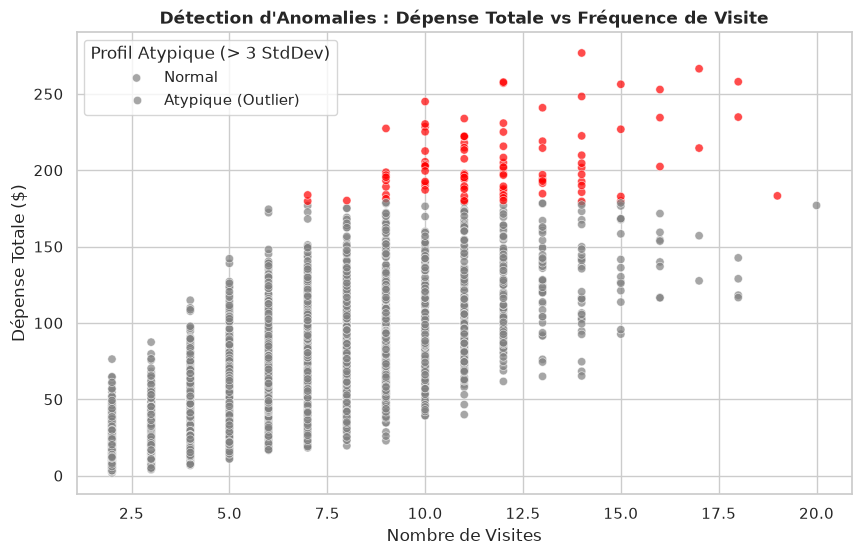

In [27]:
# 1. Calcul des scores Z (déviations standard par rapport à la moyenne) sur le profil client
client_profiles = df.groupby('client_id').agg(
    total_depense=('prix_total', 'sum'),
    nb_visites=('ticket_id', 'nunique'),
    panier_moyen=('prix_total', lambda x: x.sum() / df.loc[x.index, 'ticket_id'].nunique()),
    taux_promo=('promotion', 'mean'),
    age=('age', 'first'),
    sexe=('sexe', 'first')
).reset_index()

# Standardisation des variables pour repérer les déviations
from scipy.stats import zscore
client_profiles['z_depense'] = zscore(client_profiles['total_depense'])
client_profiles['z_panier'] = zscore(client_profiles['panier_moyen'])

# Seuil d'anomalie : Z-score > 3 (3 déviations standard au-dessus de la moyenne)
anomalies = client_profiles[(client_profiles['z_depense'] > 3) | (client_profiles['z_panier'] > 3)]

print(f"Nombre d'individus identifiés comme 'Outliers / Profils Atypiques' : {len(anomalies)} / {len(client_profiles)}")
print("\n--- ÉCHANTILLON DES PROFILS ATYPIQUES (BALEINES / ACHATEURS EXTRÊMES) ---")
display(anomalies[['client_id', 'sexe', 'age', 'total_depense', 'panier_moyen', 'taux_promo']].head(10))

# Visualisation des Outliers
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=client_profiles, 
    x='nb_visites', 
    y='total_depense', 
    hue=(client_profiles['z_depense'] > 3), 
    palette={False: 'grey', True: 'red'},
    alpha=0.7
)
plt.title("Détection d'Anomalies : Dépense Totale vs Fréquence de Visite", fontweight='bold')
plt.xlabel("Nombre de Visites")
plt.ylabel("Dépense Totale ($)")
plt.legend(title="Profil Atypique (> 3 StdDev)", labels=['Normal', 'Atypique (Outlier)'])
plt.show()

In [26]:
df.describe(include='all')

,ticket_id,client_id,age,sexe,quartier,type_client,date_achat,heure_achat,jour_semaine,mois,...,position_rayon,niveau_rayon,quantite,prix_unitaire,prix_total,promotion,taux_reduction,heure_num,tranche_age,segment_demo
count,100233,100233,98595.000000,100233,99283,100233,100233,100233,100233,100233.000000,...,100233,100233,100233.000000,100233.000000,100233.000000,100233.000000,100233.000000,100233.000000,98595,98595
unique,32729,6000,NaN,2,12,3,NaN,720,7,NaN,...,32,3,NaN,NaN,NaN,NaN,NaN,NaN,5,10
top,T016076,C003004,NaN,F,Kadutu,Régulier,NaN,10:59,Samedi,NaN,...,position_02,milieu,NaN,NaN,NaN,NaN,NaN,NaN,36-50,F (36-50)
freq,15,80,NaN,54672,18625,62125,NaN,252,23548,NaN,...,11641,51236,NaN,NaN,NaN,NaN,NaN,NaN,43774,23911
mean,NaN,NaN,42.164603,NaN,NaN,NaN,2025-07-10 19:26:15.612822,NaN,NaN,6.811439,...,NaN,NaN,1.760179,1.913512,3.280537,0.158660,0.027972,13.189429,NaN,NaN
min,NaN,NaN,18.000000,NaN,NaN,NaN,2025-01-01 00:00:00,NaN,NaN,1.000000,...,NaN,NaN,1.000000,0.500000,0.300000,0.000000,0.000000,8.000000,NaN,NaN
25%,NaN,NaN,34.000000,NaN,NaN,NaN,2025-04-11 00:00:00,NaN,NaN,4.000000,...,NaN,NaN,1.000000,1.000000,1.500000,0.000000,0.000000,10.000000,NaN,NaN
50%,NaN,NaN,42.000000,NaN,NaN,NaN,2025-07-12 00:00:00,NaN,NaN,7.000000,...,NaN,NaN,2.000000,1.500000,2.500000,0.000000,0.000000,13.000000,NaN,NaN
75%,NaN,NaN,51.000000,NaN,NaN,NaN,2025-10-11 00:00:00,NaN,NaN,10.000000,...,NaN,NaN,2.000000,2.250000,4.000000,0.000000,0.000000,16.000000,NaN,NaN
max,NaN,NaN,70.000000,NaN,NaN,NaN,2025-12-31 00:00:00,NaN,NaN,12.000000,...,NaN,NaN,6.000000,8.750000,43.750000,1.000000,0.400000,19.000000,NaN,NaN
